In [1]:
%pip install -r requirements-offline.txt --quiet

/home/coding/projects/datascience-metrology/.claude/worktrees/issue-32/.check-env/bin/python: No module named pip


Note: you may need to restart the kernel to use updated packages.


# Solution — Module M7: ทำงานอัตโนมัติ

เปิดเผยหลังจบแล็บ — เทียบกับของตัวเอง โฟกัสที่โครงสร้างลูปและการเขียนไฟล์

In [2]:
import pandas as pd
import numpy as np
from pathlib import Path


def repo_root() -> Path:
    """หา repo root โดยไล่ขึ้นจาก cwd."""
    for p in (Path.cwd(), *Path.cwd().parents):
        if (p / "requirements-offline.txt").exists():
            return p
    raise SystemExit(
        "ไม่พบ repo root — เปิด JupyterLab จาก repo root (uv run jupyter lab)")

DATA = repo_root() / "datasets"

pm25 = pd.read_csv(DATA / "pcd_pm25_2025"
                   / "pm25_daily_2025_15stations.csv")
pm25["date"] = pd.to_datetime(pm25["observation_date"])

## ส่วนที่ 1 — เตรียมเทมเพลต (1 สถานี)

In [3]:
pm25["month"] = pm25["date"].dt.month

one = pm25[pm25["station_code"] == "05T"]
summary = one.groupby("month").agg(
    mean_pm25=("measured_value", "mean"),
    max_pm25=("measured_value", "max"),
)
summary.round(1).head(4)

,mean_pm25,max_pm25
month,,
1,42.8,73.7
2,34.7,64.1
3,28.6,65.2
4,17.8,30.8


**1.1** ดูตาราง: เดือนที่ max สูงสุด (ราวมี.ค.–เม.ย. — ฤดูเผา) mean
ของเดือนนั้นก็สูงสุดด้วย แต่มีเดือนที่ max สูงลอย ๆ จากเหตุการณ์วันเดียว
ทั้งที่ mean ธรรมดา — นี่คือเหตุผลที่รายงานคุณภาพอากาศต้องรายงานทั้ง
"ระดับปกติ" (mean) และ "วันแย่ที่สุด" (max) คนละความหมาย

## ส่วนที่ 2 — วนทุกสถานี เขียนไฟล์อัตโนมัติ

In [4]:
outputs = Path("outputs")
outputs.mkdir(exist_ok=True)

for code, group in pm25.groupby("station_code"):
    summary = group.groupby("month").agg(
        mean_pm25=("measured_value", "mean"),
        max_pm25=("measured_value", "max"),
    )
    summary.round(1).to_csv(outputs / f"station_{code}.csv")

print(f"เขียนแล้ว {len(list(outputs.glob('station_*.csv')))} ไฟล์")

เขียนแล้ว 15 ไฟล์


**2.1** ศูนย์จุด — ลูปวนตามจำนวนกลุ่มที่ข้อมูลมีเอง สคริปต์เดิม
รองรับข้อมูลโตได้ทันที (สิ่งที่ต้องเปลี่ยนคือหน้าจอไม่พอแสดงไฟล์ทั้งหมด)

## ส่วนที่ 3 — อ่านกลับมารวม

In [5]:
frames = []
for path in sorted(outputs.glob("station_*.csv")):
    one = pd.read_csv(path)
    one["station"] = path.stem.removeprefix("station_")
    frames.append(one)

combined = pd.concat(frames, ignore_index=True)
print(f"ได้ {len(combined):,} แถว × {combined.shape[1]} คอลัมน์")

ได้ 180 แถว × 4 คอลัมน์


**3.1** เพราะการแตกและการรวมเป็นการย้ายแถวที่**ไม่กรองไม่สรุป** —
แต่ละไฟล์เก็บทุกแถวของสถานีตัวเอง (365 × 15 = 5,475) และ concat นำกลับครบ
สิ่งที่ทำให้แถวหายได้คือการกรอง/ตัดซ้ำระหว่างทาง — จึงต้องเช็คจำนวนแถว
ก่อน-หลังเป็นนิสัย (ข้อนี้มาจาก M3)

## ส่วนที่ 4 — กราฟอัตโนมัติ

findfont: Font family 'Noto Sans Thai' not found.


findfont: Font family 'Leelawadee UI' not found.


findfont: Font family 'Noto Sans Thai' not found.


findfont: Font family 'Leelawadee UI' not found.


findfont: Font family 'Noto Sans Thai' not found.


...

findfont: Font family 'Leelawadee UI' not found.


findfont: Font family 'Noto Sans Thai' not found.


findfont: Font family 'Leelawadee UI' not found.


findfont: Font family 'Noto Sans Thai' not found.


findfont: Font family 'Leelawadee UI' not found.


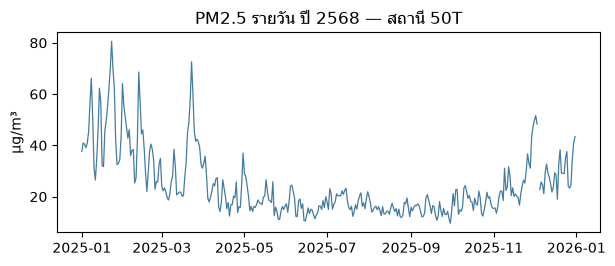

findfont: Font family 'Noto Sans Thai' not found.


findfont: Font family 'Leelawadee UI' not found.


findfont: Font family 'Noto Sans Thai' not found.


findfont: Font family 'Leelawadee UI' not found.


findfont: Font family 'Noto Sans Thai' not found.


...

findfont: Font family 'Leelawadee UI' not found.


findfont: Font family 'Noto Sans Thai' not found.


findfont: Font family 'Leelawadee UI' not found.


findfont: Font family 'Noto Sans Thai' not found.


findfont: Font family 'Leelawadee UI' not found.


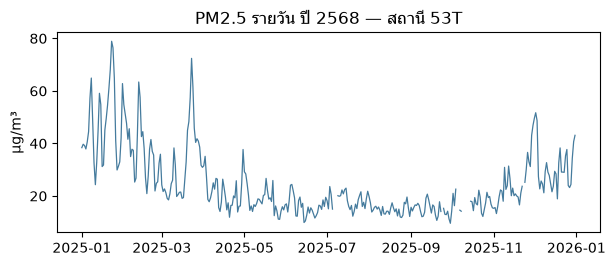

findfont: Font family 'Noto Sans Thai' not found.


findfont: Font family 'Leelawadee UI' not found.


findfont: Font family 'Noto Sans Thai' not found.


findfont: Font family 'Leelawadee UI' not found.


findfont: Font family 'Noto Sans Thai' not found.


...

findfont: Font family 'Leelawadee UI' not found.


findfont: Font family 'Noto Sans Thai' not found.


findfont: Font family 'Leelawadee UI' not found.


findfont: Font family 'Noto Sans Thai' not found.


findfont: Font family 'Leelawadee UI' not found.


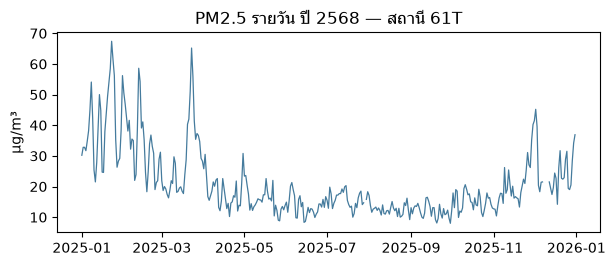

In [6]:
import matplotlib.pyplot as plt  # noqa: E402

plt.rcParams["font.family"] = [
    "DejaVu Sans", "Noto Sans Thai", "Leelawadee UI", "Tahoma",
]

for code in ["50T", "53T", "61T"]:
    one = pm25[pm25["station_code"] == code]
    fig, ax = plt.subplots(figsize=(7, 2.6))
    ax.plot(one["date"], one["measured_value"], color="#457b9d",
            lw=0.9)
    ax.set_title(f"PM2.5 รายวัน ปี 2568 — สถานี {code}")
    ax.set_ylabel("µg/m³")
    plt.savefig(outputs / f"chart_{code}.png", dpi=120,
                bbox_inches="tight")
    plt.show()

**4.1** จังหวะฤดูคล้ายกัน (สูงช่วงต้นปี ต่ำกลางปี — ฤดูเผาก่อนฝน) —
แต่ระดับความรุนแรงต่างกันตามพื้นที่ สำหรับการแจ้งเตือน ควรใช้ค่าดิบหรือ
moving average สั้น (เช่น 3-7 วัน) เพราะการเตือนต้อง**เร็วกว่า**ที่เส้นเรียบ
จะตอบสนอง — ย้ำบทเรียน M6: ความกว้างของหน้าต่าง = การเลือกเร็ว vs นิ่ง

## ส่วนที่ 5 — แบบฝึกปิดท้าย: reproduce a figure (Anscombe 1973)

งานปิดคอร์ส: สร้างผลงานชิ้นโบว์แดงของสถิติขึ้นมาใหม่ด้วยทักษะจากทุกโมดูล —
โหลดข้อมูล (M2) · กราฟ (M4) · สถิติ (M5) · เส้น trend (M6) · และตรวจคำตอบ
ตัวเองได้ เพราะ**คำตอบพิมพ์อยู่ในต้นฉบับ**

**หมายเหตุการอ้างอิง:** ต้นฉบับปี 1973 พิมพ์ภาพ scatter เป็น
**4 รูปแยกจากกัน ไม่ใช่กริด 2×2** — ระวาง 4 แผงในงานนี้เป็นการเรียบเรียง
ใหม่ของยุคหลัง

**Citation:** Anscombe, F. J. (1973). *Graphs in Statistical Analysis*.
The American Statistician, 27(1), 17–21. DOI: 10.1080/00031305.1973.10478966
— ตารางข้อมูลต้นฉบับ (wide: 11 แถว × 8 คอลัมน์ = 44 จุด)
จัดเก็บที่ `datasets/anscombe/anscombe_quartet.csv`


In [7]:
anscombe = pd.read_csv(DATA / "anscombe" / "anscombe_quartet.csv")
print(f"{len(anscombe)} แถว × {len(anscombe.columns)} คอลัมน์ "
      "= 4 คู่ (x, y) × 11 จุด — ตาราง wide ตามต้นฉบับ")
anscombe


11 แถว × 8 คอลัมน์ = 4 คู่ (x, y) × 11 จุด — ตาราง wide ตามต้นฉบับ


,x1,x2,x3,x4,y1,y2,y3,y4
0,10,10,10,8,8.04,9.14,7.46,6.58
1,8,8,8,8,6.95,8.14,6.77,5.76
2,13,13,13,8,7.58,8.74,12.74,7.71
3,9,9,9,8,8.81,8.77,7.11,8.84
4,11,11,11,8,8.33,9.26,7.81,8.47
5,14,14,14,8,9.96,8.10,8.84,7.04
6,6,6,6,8,7.24,6.13,6.08,5.25
7,4,4,4,19,4.26,3.10,5.39,12.50
8,12,12,12,8,10.84,9.13,8.15,5.56
9,7,7,7,8,4.82,7.26,6.42,7.91


**ภาพที่ต้องทำซ้ำ** — จุด scatter + เส้น trend ของทั้ง 4 คู่ วาดลงกริด 2×2
(เทคนิคเดียวกับ M4 ก6 แต่ 2×2 แทน 1×2):


findfont: Font family 'Noto Sans Thai' not found.


findfont: Font family 'Leelawadee UI' not found.


findfont: Font family 'Noto Sans Thai' not found.


findfont: Font family 'Leelawadee UI' not found.


findfont: Font family 'Noto Sans Thai' not found.


...

findfont: Font family 'Leelawadee UI' not found.


findfont: Font family 'Noto Sans Thai' not found.


findfont: Font family 'Leelawadee UI' not found.


findfont: Font family 'Noto Sans Thai' not found.


findfont: Font family 'Leelawadee UI' not found.


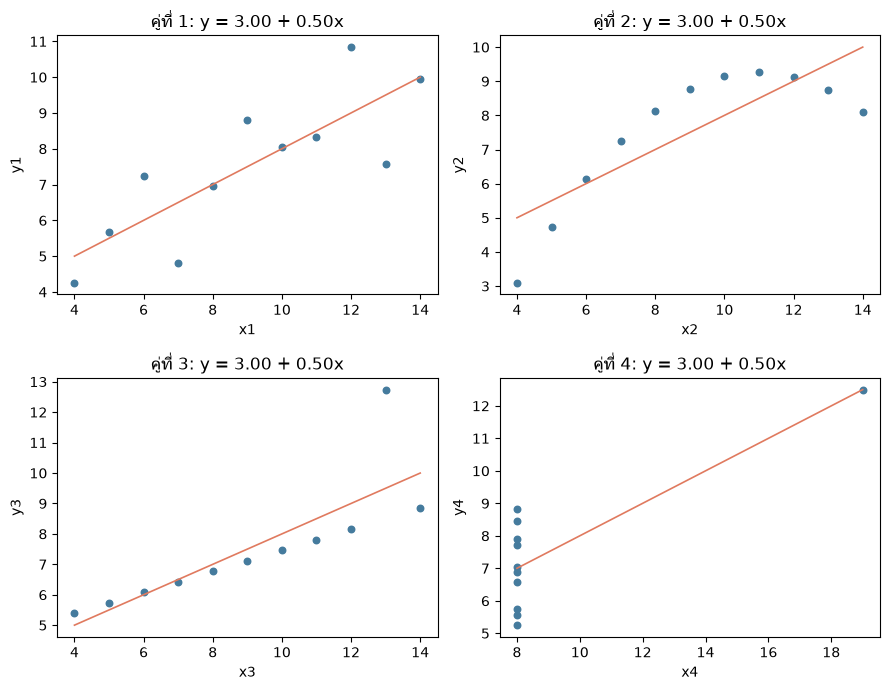

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(9, 7))

for i, ax in [(1, axes[0][0]), (2, axes[0][1]),
              (3, axes[1][0]), (4, axes[1][1])]:
    x = anscombe[f"x{i}"]
    y = anscombe[f"y{i}"]
    slope, intercept = np.polyfit(x, y, 1)      # เส้น trend จาก M6
    xs = np.array([x.min(), x.max()])           # จุดปลายสองข้างของเส้น
    ax.scatter(x, y, s=22, color="#457b9d")
    ax.plot(xs, intercept + slope * xs, color="#e07a5f", lw=1.2)
    ax.set_title(f"คู่ที่ {i}: y = {intercept:.2f} + {slope:.2f}x")
    ax.set_xlabel(f"x{i}")
    ax.set_ylabel(f"y{i}")

fig.tight_layout()
plt.show()


**ตารางสถิติสรุป** — สูตร pandas/numpy ล้วน ไม่มี scipy/sklearn (ADR-0002):
ความชัน = cov(x, y) ÷ var(x) · R² = r² เมื่อ r = cov(x, y) ÷ (sd(x) ×
sd(y)) — ทั้งหมดเป็นอัตราส่วน ddof จึงตัดกันหมด


In [9]:
rows = []
for i in [1, 2, 3, 4]:
    x = anscombe[f"x{i}"]
    y = anscombe[f"y{i}"]
    slope = x.cov(y) / x.var()             # ความชัน: cov ÷ var
    r = x.cov(y) / (x.std() * y.std())     # สหสัมพรรค์: cov ÷ (sd·sd)
    rows.append({
        "pair": i,
        "mean_x": x.mean(),
        "mean_y": y.mean(),
        "slope": slope,
        "r2": r ** 2,
    })

stats = pd.DataFrame(rows).set_index("pair")
stats.round(3)


,mean_x,mean_y,slope,r2
pair,,,,
1,9.0,7.501,0.5,0.667
2,9.0,7.501,0.5,0.666
3,9.0,7.500,0.5,0.666
4,9.0,7.501,0.5,0.667


**Self-verifying** — ต้นฉบับพิมพ์สรุปไว้แล้วว่าทุกคู่เท่ากัน: ค่าเฉลี่ย
x = 9.0 · ค่าเฉลี่ย y = 7.50 · เส้นตรงเทียบ y = 3.00 + 0.500x · R² = 0.667
(r = 0.816) ตารางข้างบนต้องตรงกับตัวเลขเหล่านี้ — ตรวจด้วยค่าเผื่อ 0.001
(ปัด 3 ตำแหน่งแล้วเทียบตรง ๆ ไม่ได้ เช่น R² จริง 0.6662 ปัดได้ 0.666)


In [10]:
expected = pd.DataFrame(
    {"mean_x": 9.0, "mean_y": 7.5, "slope": 0.5, "r2": 0.667},
    index=stats.index,
)
diff = (stats[["mean_x", "mean_y", "slope", "r2"]] - expected).abs()

assert (diff < 0.001).all().all(), "ยังไม่ตรงต้นฉบับ — กลับไปเช็คขั้นที่ 3"
print("ผ่าน — ตารางตรงกับตัวเลขที่ต้นฉบับพิมพ์ทุกค่า")
diff.round(4)


ผ่าน — ตารางตรงกับตัวเลขที่ต้นฉบับพิมพ์ทุกค่า


,mean_x,mean_y,slope,r2
pair,,,,
1,0.0,0.0009,0.0001,0.0005
2,0.0,0.0009,0.0000,0.0008
3,0.0,0.0000,0.0003,0.0007
4,0.0,0.0009,0.0001,0.0003


**คำตอบ 5.1** ตัวเลขสรุปทั้งสี่คู่เหมือนกันแทบทุกตัว แต่กราฟบอกคนละเรื่อง:
คู่ 1 เป็นความสัมพันธ์เส้นตรงจริง · คู่ 2 เป็นเส้นโค้ง — สรุปด้วยเส้นตรง
ไม่ได้ (กับดัก extrapolation ของ M6) · คู่ 3 เป็นเส้นตรงสมบูรณ์แบบ
ถ้าตัดจุดผิดปกติ 1 จุดออก — จุดเดียวฉุดทั้งค่า (บทเรียน M3/M5 เรื่องค่า
แปลก) · คู่ 4 เส้นตรง "ดูดี" เพราะจุดเดียวที่อยู่ไกล — ตารางทั้งหมดถูก
กำหนดโดย 1 จุด

บทเรียนเดียวกับทั้งคอร์ส: **ตัวเลขสรุปไม่พอ — ต้องดูกราฟเสมอ** และคำถาม
"ทำไมจึงเชื่อ" (M6) คือคำถามเดียวกับที่ ML ตอบด้วยโมเดล — วัตถุดิบที่
ผู้เรียนมีวันนี้คือสิ่งที่คอร์สต่อไปจะสร้างบน (ดูสไลด์ What's next ตอน
ปิดคลาสใน `explanation.md`)
